<a href="https://colab.research.google.com/github/jad-r-s/Jad_INFO4670_Fall2026/blob/main/JadSaboune_INFO4670_Assignment_SMS_Spam_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [1]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> A False Positive is more costly, because a blocked real message is silently lost and the user never knows it existed. For example, a bank fraud alert or a 2FA code might never arrive. A False Negative is mostly a nuisance: the user gets a promotional or phishing text that they can see, delete, or report.

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> Precision should be the primary metric, because it measures how many flagged messages are actually spam (TP / (TP + FP)). High precision means very few legitimate messages get blocked, which is the costlier error from Q1a. Recall still matters, but it should be maximized only after precision is kept high.

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> A model that always predicts “ham” would get about 87% accuracy (100% − 13%). That number is misleading, because the model catches zero spam and has 0% recall. On imbalanced data, accuracy mostly reflects the majority class, so precision and recall are better measures of real performance.


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [2]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


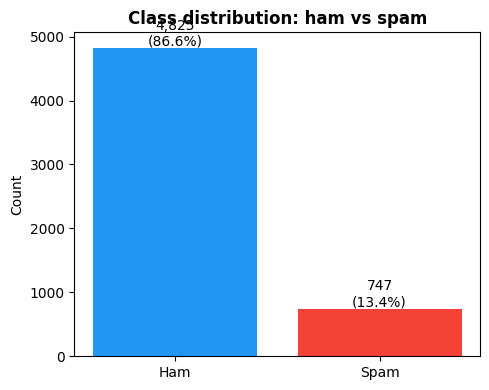

In [3]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [4]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


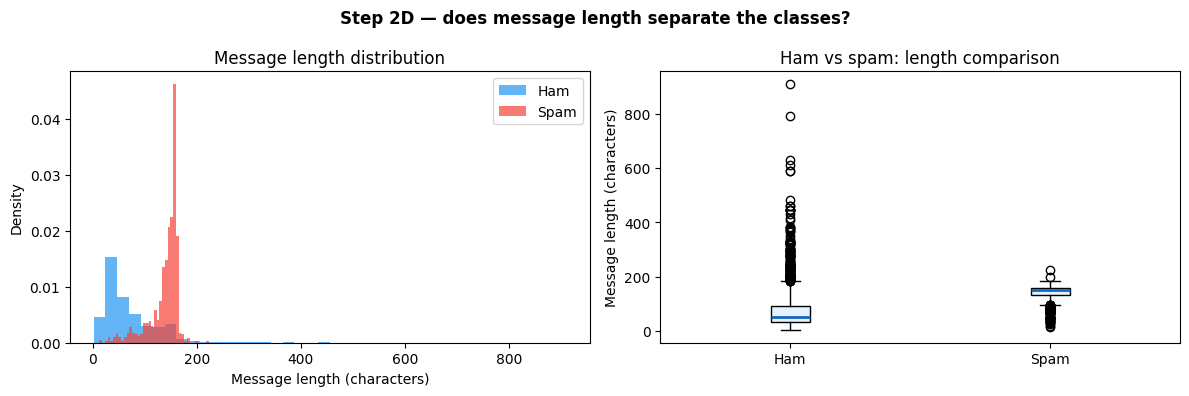

In [5]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [6]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [7]:
# Write your code here

def build_features_v2(df):
    d = build_features(df)   # keeps all 4 starter features
    msg = d['message'].str.lower()

    # --- Feature 5: contains an ALL CAPS word (3+ letters) ---
    # Uses the ORIGINAL message, because msg is lowercased
    d['has_caps_word'] = d['message'].str.contains(r'\b[A-Z]{3,}\b', regex=True).astype(int)

    # --- Feature 6: call-to-action (txt / text / reply) ---
    d['has_cta'] = msg.str.contains(r'\b(?:txt|text|reply)\b', regex=True).astype(int)

    # --- Feature 7: contains a URL or "www" ---
    d['has_url'] = msg.str.contains(r'www\.|https?://|\.com\b|\.co\.uk\b', regex=True).astype(int)

    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

# Print spam vs ham rate for all features
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_caps_word          70.4%    7.2%  +63.3%
has_cta                40.7%    2.5%  +38.2%
has_url                18.2%    0.3%  +17.9%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


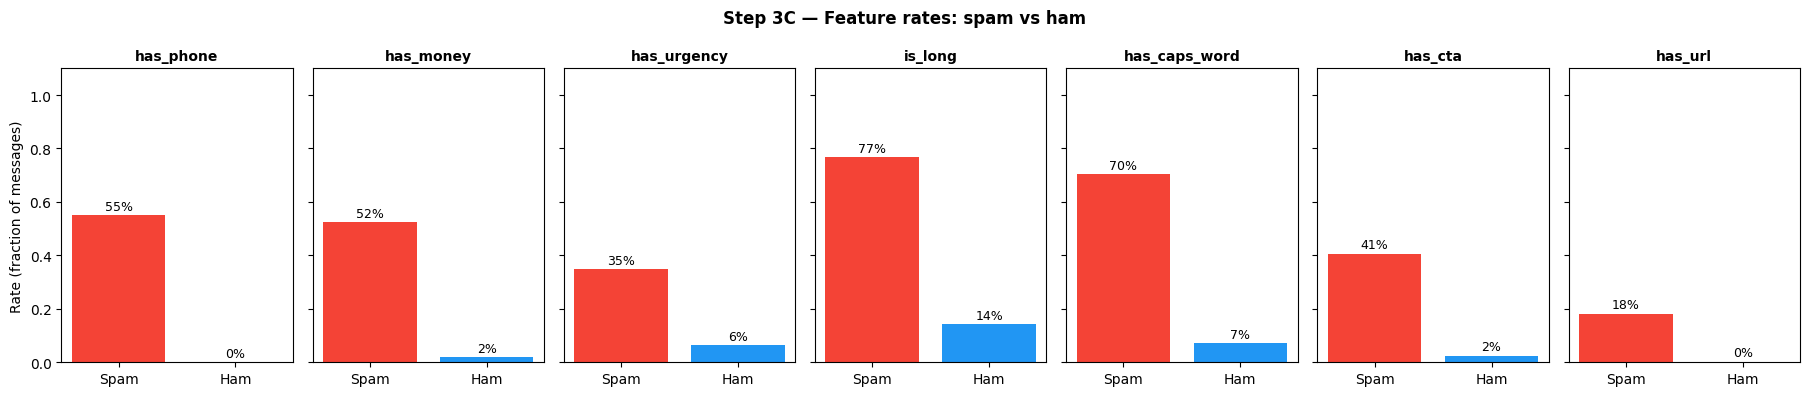

In [8]:
# Write your code here
n_features = len(feature_cols)
fig, axes = plt.subplots(1, n_features, figsize=(2.6 * n_features, 4), sharey=True)
axes = np.atleast_1d(axes)   # still works if there is only one feature

for ax, feat in zip(axes, feature_cols):
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()

    ax.bar(['Spam', 'Ham'], [sp, ha], color=['#F44336', '#2196F3'])
    ax.set_title(feat, fontsize=10, fontweight='bold')
    ax.set_ylim(0, 1.1)

    # Label each bar with its percentage
    for i, v in enumerate([sp, ha]):
        ax.text(i, v + 0.02, f'{v:.0%}', ha='center', fontsize=9)

axes[0].set_ylabel('Rate (fraction of messages)')
plt.suptitle('Step 3C — Feature rates: spam vs ham', fontweight='bold')
plt.tight_layout()
plt.show()

### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation:*
> has_caps_word: Flags messages that contain a word of 3 or more capital letters, such as “FREE”, “WIN” or “URGENT”. Spammers use capitals to grab attention and create urgency, while normal personal texts are mostly lowercase or sentence case. I expected this to show up far more often in spam than in ham.

*Feature 2 — name and explanation:*
> has_cta: Flags call-to-action words like “txt”, “text” or “reply”. Spam usually asks the reader to act (“Txt WIN to 80086”, “Reply STOP”), because the goal is a response that earns money. Ham rarely uses these words as instructions, so they should be a strong spam signal.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> has_caps_word has the largest gap: 70.4% of spam versus 7.2% of ham, a difference of 63.3 percentage points. is_long is close behind at 62.7. A large gap matters because splitting on that feature sends most spam down one branch and most ham down the other, which makes each child node much purer than the parent. Information Gain measures that drop in impurity (entropy or Gini), and the Decision Tree picks the feature with the highest gain as its root node.
The gap isn’t the only factor, though. has_phone has a smaller gap (55.2% vs 0.1%), but its “yes” branch is almost entirely spam, a nearly pure node. Because of that, it could still give the highest Information Gain and become the root.

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> A message like “Hey it’s mum, I lost my phone so this is my new number. Can you send me £50 for the bill?” would evade my features. It contains no capitalized words, so has_caps_word is 0. It never says “txt”, “text” or “reply”, so has_cta is 0, and it contains no link. Because this kind of scam copies the casual tone of a real personal message, keyword-based features can’t tell it apart from ham, and it would become a False Negative.


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [10]:
# Write your code here
X = df[feature_cols].values
y = df['spam'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f'Features used: {feature_cols}')
print()
print(f'Training set : {X_train.shape[0]:,} messages  |  spam rate = {y_train.mean():.1%}')
print(f'Test set     : {X_test.shape[0]:,} messages  |  spam rate = {y_test.mean():.1%}')
print(f'Overall      : {len(y):,} messages  |  spam rate = {y.mean():.1%}')

Features used: ['has_phone', 'has_money', 'has_urgency', 'is_long', 'has_caps_word', 'has_cta', 'has_url']

Training set : 4,179 messages  |  spam rate = 13.4%
Test set     : 1,393 messages  |  spam rate = 13.4%
Overall      : 5,572 messages  |  spam rate = 13.4%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> stratify=y makes the training and test sets keep the same class balance as the full dataset, about 13% spam in each. Without it, a random split on imbalanced data could by chance put noticeably more or fewer spam messages in the test set. The model would then train on a different spam rate than it’s tested on, and metrics like precision and recall would be unreliable, either too optimistic or too pessimistic depending on the luck of the split.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> I would prefer cross-validation when the dataset is small, because a single 25% test set would then contain very few spam messages and the scores would depend heavily on which messages happened to land in it. With k-fold cross-validation, every message is used for testing exactly once and the results are averaged over k folds, which gives a more stable estimate of performance. It is also the better choice when tuning hyperparameters such as tree depth, because it avoids choosing settings that only work well on one lucky split.


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Decision Tree trained
  Depth          : 4
  Number of leaves: 15
  Root feature   : has_caps_word

=== Decision rules ===
|--- has_caps_word <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_url <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_url >  0.50
|   |   |   |--- has_urgency <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_urgency >  0.50
|   |   |   |   |--- class: 0
|   |--- has_phone >  0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_cta <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_cta >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- class: 1
|--- has_caps_word >  0.50
|   |--- has_money <= 0.50
|   |   |--- has_phone <= 0.50
|   |   |   |--- has_cta <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_cta >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_phone >  0.50
|   |   |   |--- i

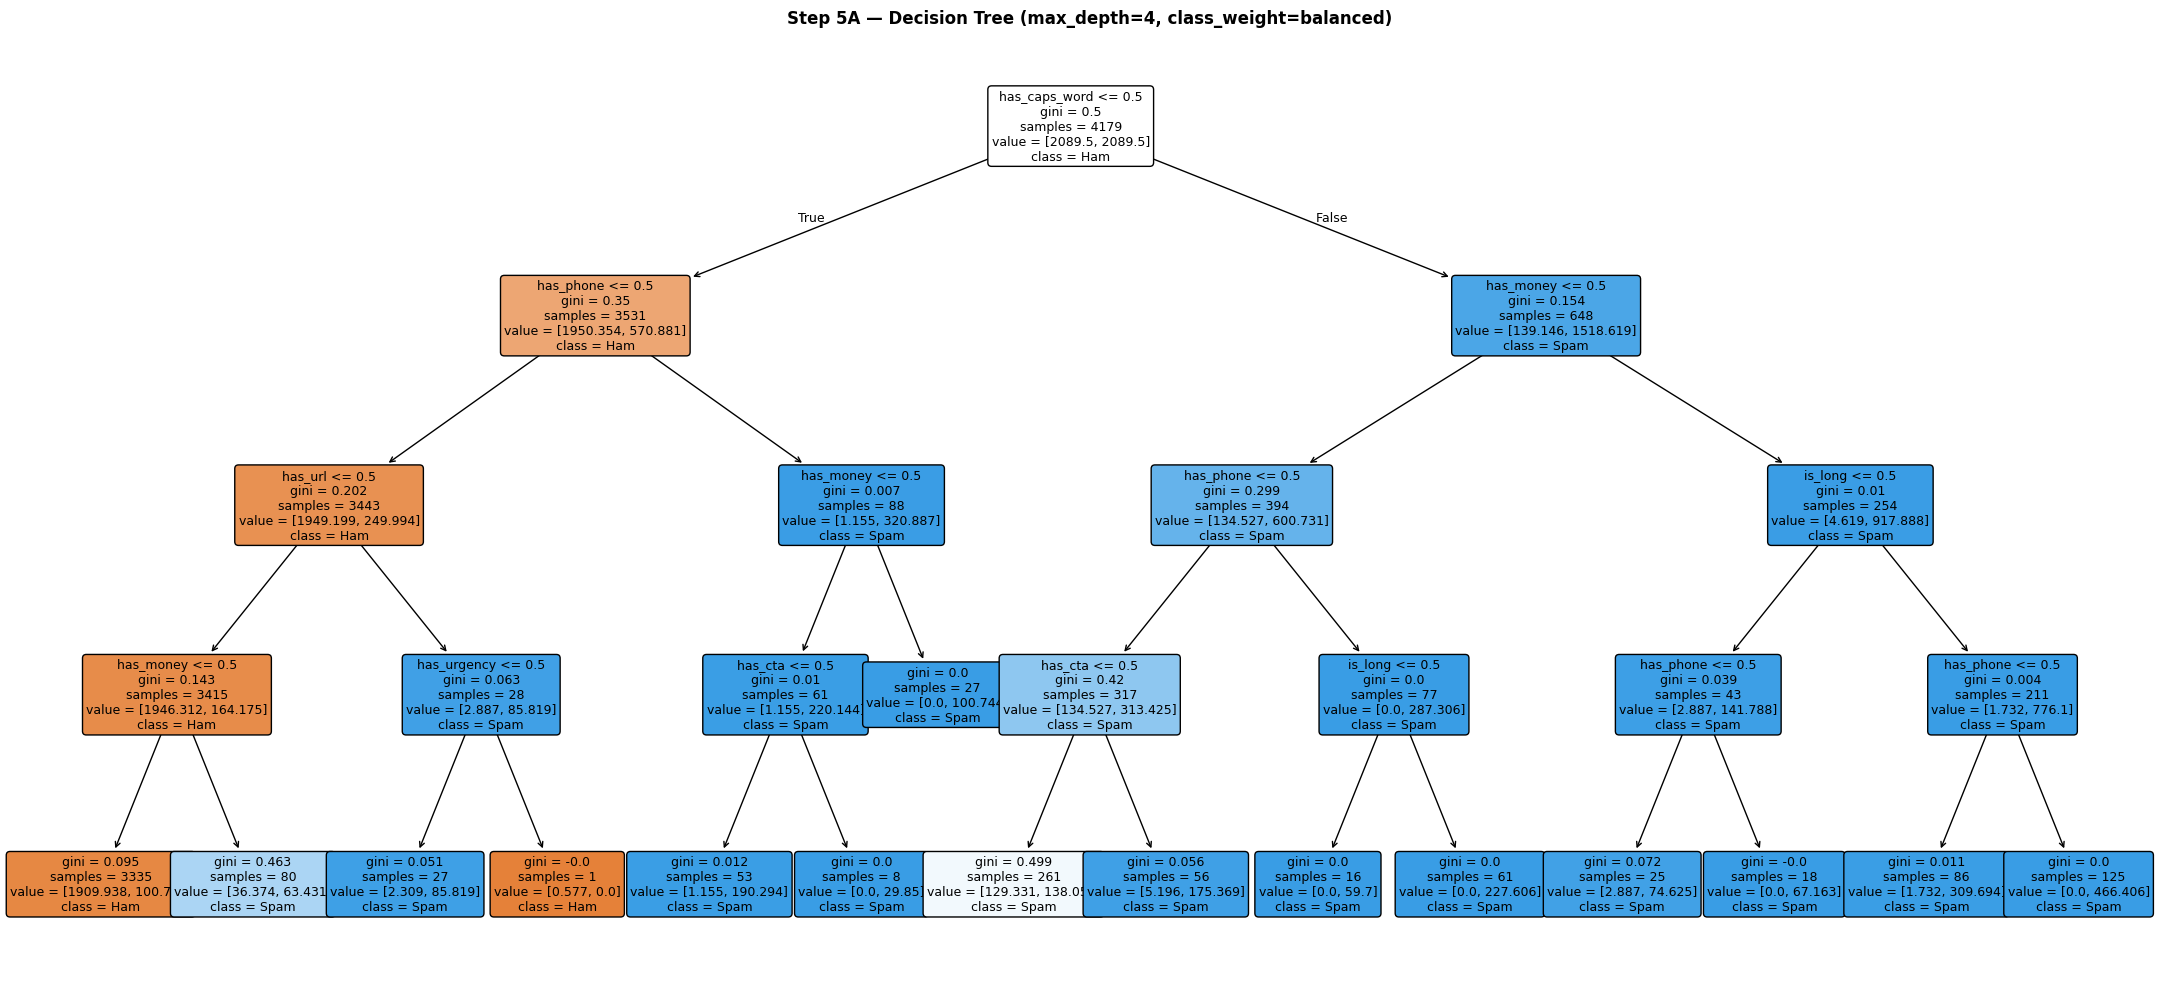

In [11]:
# Write your code here
# Train the Decision Tree
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt_model.fit(X_train, y_train)

print(f'Decision Tree trained')
print(f'  Depth          : {dt_model.get_depth()}')
print(f'  Number of leaves: {dt_model.get_n_leaves()}')
print(f'  Root feature   : {feature_cols[dt_model.tree_.feature[0]]}')
print()

# Text rules
print('=== Decision rules ===')
print(export_text(dt_model, feature_names=feature_cols))

# Visualize the tree
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(dt_model,
          feature_names=feature_cols,
          class_names=['Ham', 'Spam'],
          filled=True,
          rounded=True,
          fontsize=9,
          impurity=True,
          ax=ax)
ax.set_title('Step 5A — Decision Tree (max_depth=4, class_weight=balanced)', fontweight='bold')
plt.tight_layout()
plt.show()

### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


Feature importances (highest first):
  has_caps_word    0.562
  has_phone        0.277
  has_url          0.080
  has_money        0.054
  has_cta          0.026
  has_urgency      0.001
  is_long          0.000


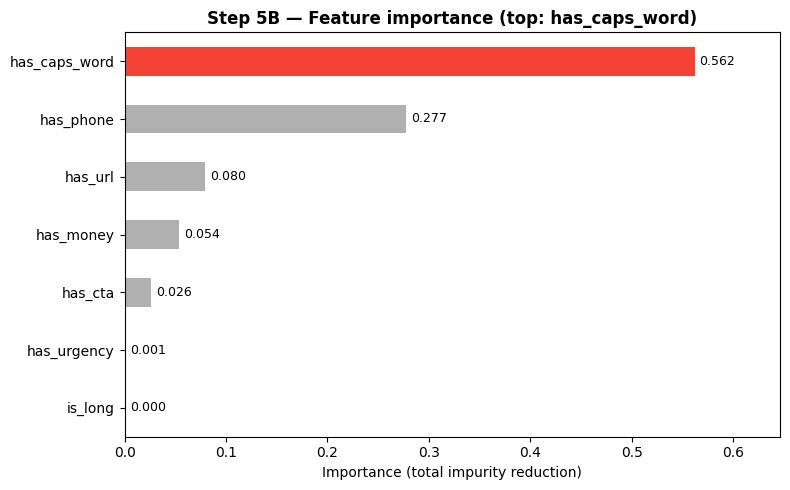

In [12]:
# Write your code here
# Get feature importances from the trained tree
importances = pd.Series(dt_model.feature_importances_, index=feature_cols).sort_values()

# Highest bar red, all others gray
colors = ['#F44336' if v == importances.max() else '#B0B0B0' for v in importances]

print('Feature importances (highest first):')
for feat, imp in importances.sort_values(ascending=False).items():
    print(f'  {feat:<16} {imp:.3f}')

fig, ax = plt.subplots(figsize=(8, 5))
importances.plot(kind='barh', color=colors, ax=ax)

# Label each bar with its value
for i, v in enumerate(importances):
    ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)

ax.set_xlabel('Importance (total impurity reduction)')
ax.set_title(f'Step 5B — Feature importance (top: {importances.idxmax()})', fontweight='bold')
ax.set_xlim(0, importances.max() * 1.15)
plt.tight_layout()
plt.show()

### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


depth  leaves  train_f1  test_f1   gap
    1       2     0.674    0.580 0.093
    2       4     0.761    0.715 0.046
    3       8     0.779    0.729 0.051
    4      15     0.760    0.706 0.053
    5      24     0.916    0.893 0.023
    6      36     0.901    0.881 0.020
 None      54     0.907    0.890 0.017


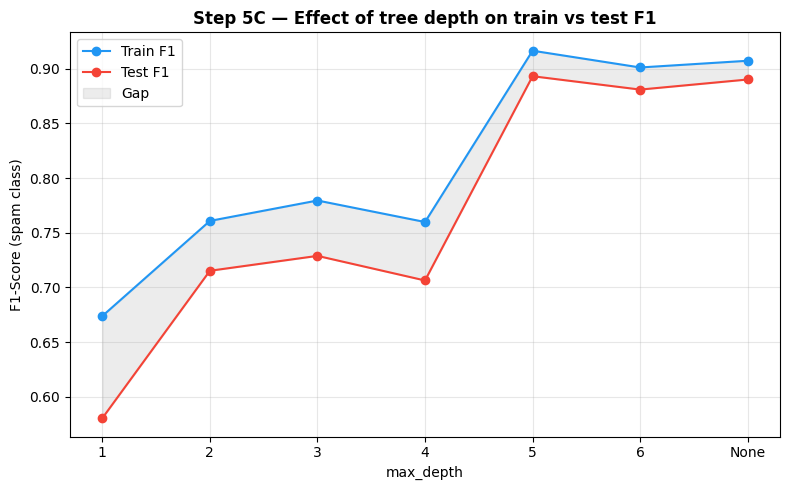


Gap grows the most going to depth = 3


In [13]:
# Write your code here
depths = [1, 2, 3, 4, 5, 6, None]
results = []

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight='balanced')
    tree.fit(X_train, y_train)

    train_f1 = f1_score(y_train, tree.predict(X_train))
    test_f1  = f1_score(y_test,  tree.predict(X_test))

    results.append({
        'depth'   : 'None' if d is None else str(d),
        'leaves'  : tree.get_n_leaves(),
        'train_f1': train_f1,
        'test_f1' : test_f1,
        'gap'     : train_f1 - test_f1
    })

res_df = pd.DataFrame(results)
print(res_df.to_string(index=False, float_format='%.3f'))

# Plot train vs test F1
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(res_df['depth'], res_df['train_f1'], marker='o', color='#2196F3', label='Train F1')
ax.plot(res_df['depth'], res_df['test_f1'],  marker='o', color='#F44336', label='Test F1')
ax.fill_between(res_df['depth'], res_df['train_f1'], res_df['test_f1'],
                color='gray', alpha=0.15, label='Gap')

ax.set_xlabel('max_depth')
ax.set_ylabel('F1-Score (spam class)')
ax.set_title('Step 5C — Effect of tree depth on train vs test F1', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Find where the gap starts to widen
widen_idx = res_df['gap'].diff().idxmax()
print(f'\nGap grows the most going to depth = {res_df.loc[widen_idx, "depth"]}')

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [14]:
# Write your code here
# Train Bernoulli Naive Bayes
nb_model = BernoulliNB()
nb_model.fit(X_train, y_train)

print('Bernoulli Naive Bayes trained')
print(f'  Class priors: Ham = {np.exp(nb_model.class_log_prior_[0]):.1%}, '
      f'Spam = {np.exp(nb_model.class_log_prior_[1]):.1%}')
print()

# P(feature = 1 | class) learned for each feature
probs = pd.DataFrame(np.exp(nb_model.feature_log_prob_).T,
                     index=feature_cols, columns=['P(f=1|Ham)', 'P(f=1|Spam)'])
print(probs.to_string(float_format='%.3f'))

Bernoulli Naive Bayes trained
  Class priors: Ham = 86.6%, Spam = 13.4%

               P(f=1|Ham)  P(f=1|Spam)
has_phone           0.001        0.546
has_money           0.021        0.527
has_urgency         0.067        0.349
is_long             0.141        0.770
has_caps_word       0.067        0.726
has_cta             0.026        0.416
has_url             0.002        0.189


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


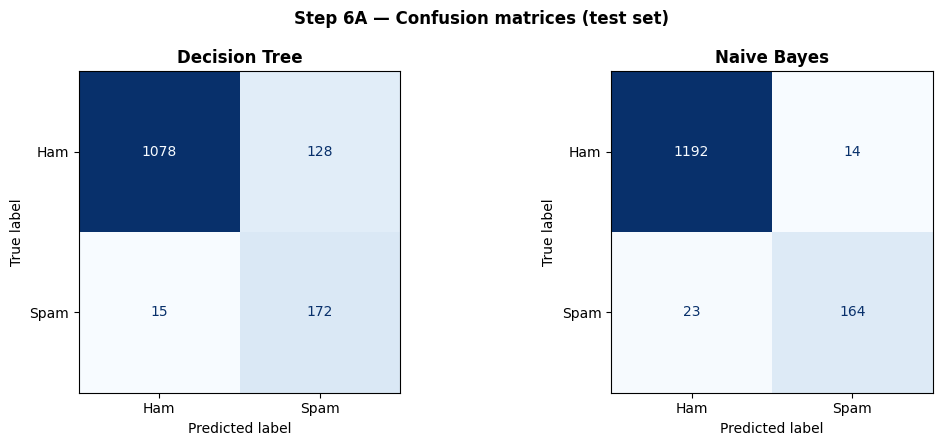

Model              TP    FP    FN     TN
----------------------------------------
Decision Tree     172   128    15   1078
Naive Bayes       164    14    23   1192


In [15]:
# Write your code here
# Predictions from both models
y_pred_dt = dt_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)

models = {'Decision Tree': y_pred_dt, 'Naive Bayes': y_pred_nb}

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_pred) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ham', 'Spam'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name, fontweight='bold')
plt.suptitle('Step 6A — Confusion matrices (test set)', fontweight='bold')
plt.tight_layout()
plt.show()

# Print TP, FP, FN, TN
print(f'{"Model":<15} {"TP":>5} {"FP":>5} {"FN":>5} {"TN":>6}')
print('-' * 40)
for name, y_pred in models.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f'{name:<15} {tp:>5} {fp:>5} {fn:>5} {tn:>6}')

### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree     0.897      0.573   0.920     0.706
  Naive Bayes     0.973      0.921   0.877     0.899


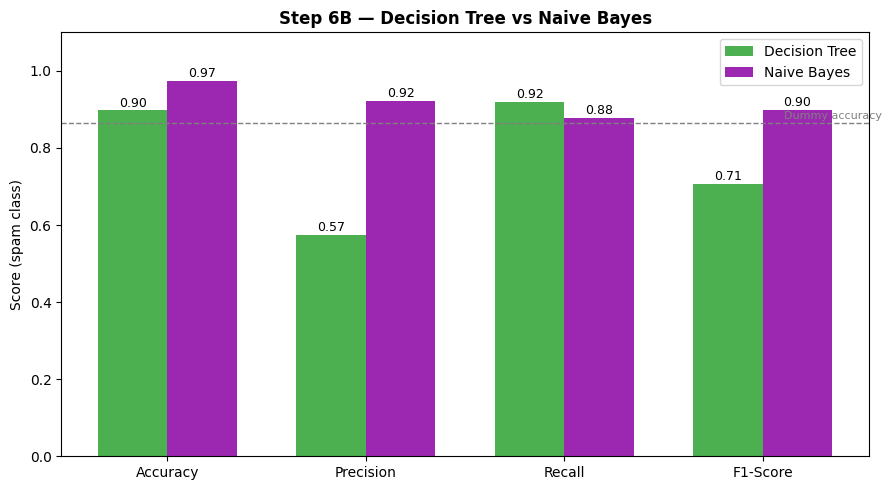


Best on primary metric (Precision): Naive Bayes


In [16]:
# Write your code here
# Build metrics table
rows = []
for name, y_pred in models.items():
    rows.append({
        'Model'    : name,
        'Accuracy' : accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall'   : recall_score(y_test, y_pred, zero_division=0),
        'F1-Score' : f1_score(y_test, y_pred, zero_division=0),
    })

metrics_df = pd.DataFrame(rows)
print(metrics_df.to_string(index=False, float_format='%.3f'))

# Grouped bar chart
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metric_names))
width = 0.35
colors = ['#4CAF50', '#9C27B0']

fig, ax = plt.subplots(figsize=(9, 5))
for i, (_, row) in enumerate(metrics_df.iterrows()):
    vals = row[metric_names].values.astype(float)
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=row['Model'], color=colors[i])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.01, f'{v:.2f}',
                ha='center', fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1.1)
ax.set_ylabel('Score (spam class)')
ax.set_title('Step 6B — Decision Tree vs Naive Bayes', fontweight='bold')
ax.axhline(0.866, color='gray', linestyle='--', linewidth=1)
ax.text(3.6, 0.875, 'Dummy accuracy', fontsize=8, color='gray', ha='right')
ax.legend()
plt.tight_layout()
plt.show()

# Primary metric from Q1b
best = metrics_df.loc[metrics_df['Precision'].idxmax(), 'Model']
print(f'\nBest on primary metric (Precision): {best}')

### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [17]:
# Write your code here
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    'Decision Tree': DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced'),
    'Naive Bayes'  : BernoulliNB(),
}

print('5-fold stratified cross-validation (F1, spam class)')
print('-' * 60)
cv_results = {}
for name, model in cv_models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='f1')
    cv_results[name] = scores
    fold_str = '  '.join(f'{s:.3f}' for s in scores)
    print(f'{name:<15} folds: {fold_str}')
    print(f'{"":<15} mean F1 = {scores.mean():.3f}  (± {scores.std():.3f})')
    print()

5-fold stratified cross-validation (F1, spam class)
------------------------------------------------------------
Decision Tree   folds: 0.889  0.851  0.893  0.830  0.874
                mean F1 = 0.867  (± 0.024)

Naive Bayes     folds: 0.910  0.899  0.899  0.897  0.899
                mean F1 = 0.901  (± 0.005)



### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> It caught 172 spam messages (TP), let 15 spam messages slip through (FN), and wrongly blocked 128 legitimate messages (FP).

*Naive Bayes:*
> It caught 164 spam messages (TP), let 23 spam messages slip through (FN), and wrongly blocked only 14 legitimate messages (FP).

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
> Naive Bayes clearly wins on Precision, my primary metric: 0.92 versus 0.57 for the Decision Tree, about 35 percentage points higher. In practical terms, it blocked 14 legitimate messages instead of 128. Cross-validation confirms that Naive Bayes is the stronger model: its mean F1 is 0.901 versus 0.867. It is also much more stable across folds (±0.005 versus ±0.024), so its advantage doesn’t depend on one lucky split.

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> I recommend the Naive Bayes model for the carrier’s spam filter. It reaches a precision of 0.92 and wrongly blocked only 14 of 1,206 legitimate messages (about 1%), compared with 128 for the Decision Tree. Its main weakness is that it misses 23 of 187 spam messages (about 12%), especially spam that has no obvious trigger words. To improve it, I would replace the seven keyword features with TF-IDF word features, so the model learns from every word in a message instead of a short hand-picked list.

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> has_caps_word would likely fail on modern spam, because professional scams copy the style of real banks and companies and use normal sentence case instead of “FREE” or “WIN”. has_cta would also fail, because modern spam rarely says “txt” or “reply”; it asks users to click a link or “verify your account”, phrases the feature doesn’t look for. Both features were built for the loud style of 2010s SMS spam, so they would stay at 0 for modern spam that is designed to look legitimate.
